Veriler başarıyla temizlendi!
-------------------------------------------------
İstatistikler hesaplanıyor...
        Manisa(Ahmetli)-1751  Manisa(Akhisar)-1118  Manisa(Alaşehir)-1127  \
count              44.000000             44.000000              44.000000   
mean             1305.818182          48906.568182            1125.795455   
std              1496.850527          44690.786872             880.912148   
min                 0.000000              0.000000             234.000000   
25%               209.000000              0.000000             530.500000   
50%               787.500000          49617.500000             912.000000   
75%              1587.000000          85402.250000            1541.750000   
max              6306.000000         160815.000000            5265.000000   
fark             6306.000000         160815.000000            5031.000000   
medyan            787.500000          49617.500000             912.000000   

        Manisa(Demirci)-1269  Manisa(Gölma

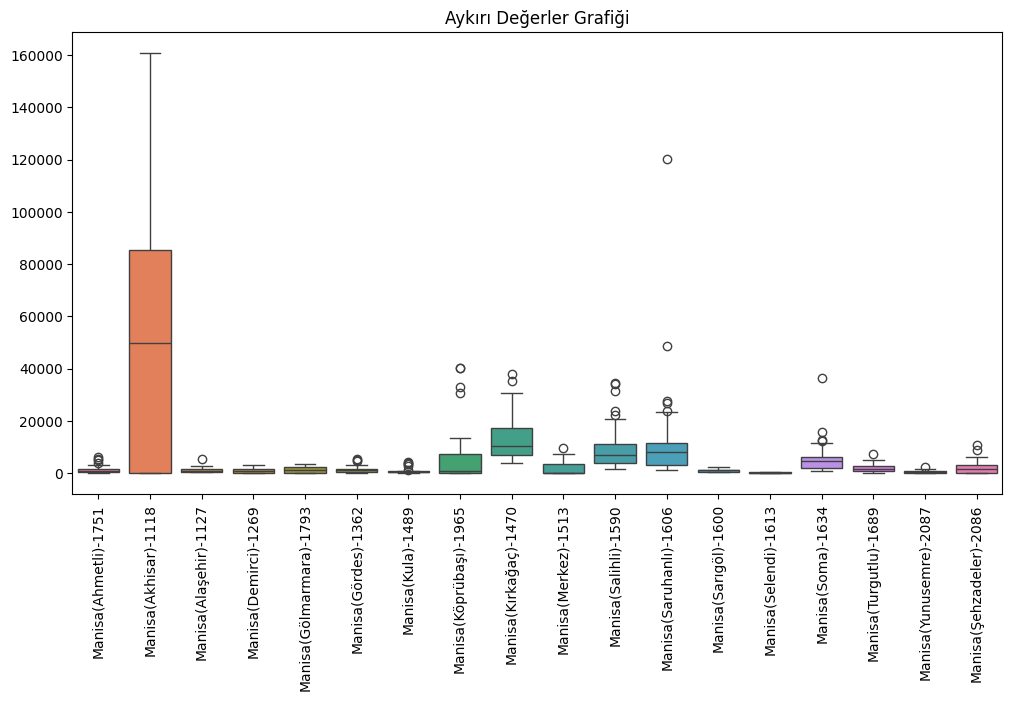

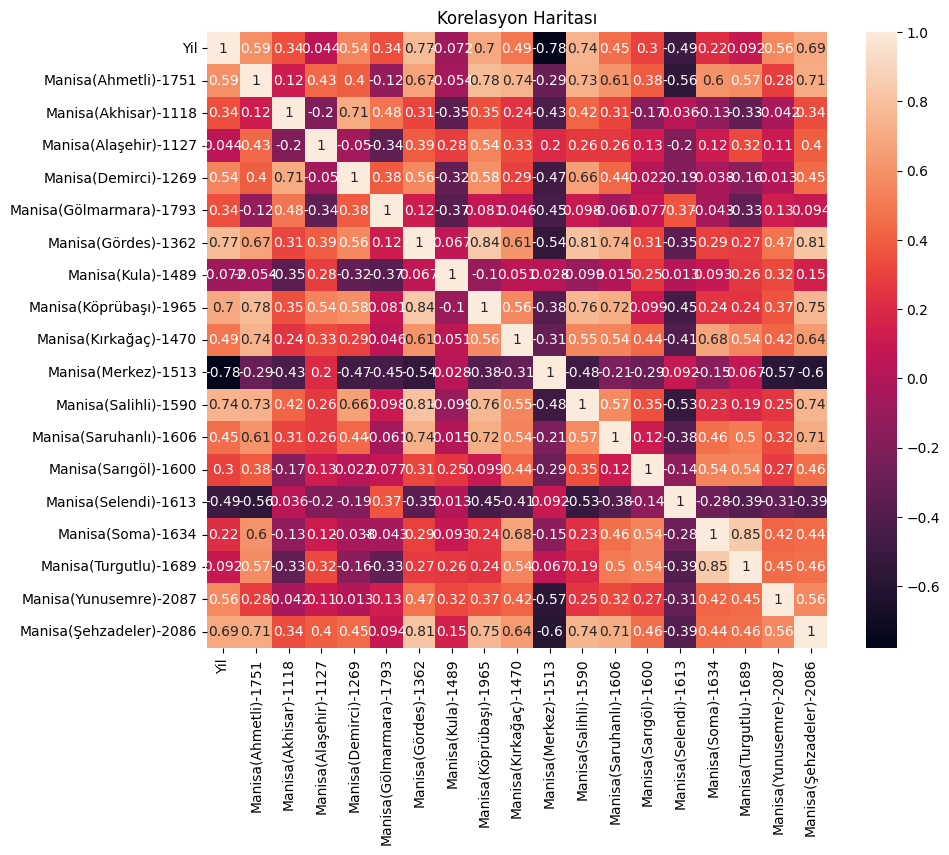

Modelleme bitti.
-------------------------------------------------
Modellerin Puanları:
K-Means Puanı: 0.2227183557780742
Hiyerarşik Puanı: 0.2123197096663197


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score

# 1. VERİ TEMİZLEME KISMI
# Dosyayı okuyorum
veri = pd.read_csv(r"/content/pivotemre.csv", sep='|', header=None)

# 1. satırdaki ilçeleri bir listeye alıyorum
ilce_isimleri = []
for i in range(3, 21):
    isim = veri.iloc[1, i]
    # boş değilse listeye ekle
    if pd.isna(isim) == False:
        ilce_isimleri.append(isim)

# Sütun isimlerini oluşturuyorum
sutun_adlari = ["Kategori", "Urun", "Yil"]
for ilce in ilce_isimleri:
    sutun_adlari.append(ilce)

# Veriler 4. satırdan başlıyor, o kısmı kesip alıyorum
temiz_veri = veri.iloc[4: , 0:len(sutun_adlari)].copy()
temiz_veri.columns = sutun_adlari

# Yıl kısmını düzeltiyorum
temiz_veri['Yil'] = pd.to_numeric(temiz_veri['Yil'], errors='coerce')
temiz_veri = temiz_veri.dropna(subset=['Yil']) # yılı boş olanları sildim
temiz_veri['Yil'] = temiz_veri['Yil'].astype(int) # tam sayı yaptım

# İlçe sütunlarındaki boşlukları 0 yapıyorum
for ilce in ilce_isimleri:
    temiz_veri[ilce] = pd.to_numeric(temiz_veri[ilce], errors='coerce')
    temiz_veri[ilce] = temiz_veri[ilce].fillna(0)

print("Veriler başarıyla temizlendi!")
print("-------------------------------------------------")


# 2. İSTATİSTİKLER KISMI
print("İstatistikler hesaplanıyor...")
istatistik_tablosu = temiz_veri[ilce_isimleri].describe()

# en yüksekten en düşüğü çıkarıp farkı buluyorum
istatistik_tablosu.loc['fark'] = istatistik_tablosu.loc['max'] - istatistik_tablosu.loc['min']

# medyanı da ekliyorum
medyanlar = temiz_veri[ilce_isimleri].median()
istatistik_tablosu.loc['medyan'] = medyanlar

print(istatistik_tablosu)

# Kutu grafiği çizdiriyorum
plt.figure(figsize=(12, 6))
sns.boxplot(data=temiz_veri[ilce_isimleri])
plt.title("Aykırı Değerler Grafiği")
plt.xticks(rotation=90)
plt.show()

# Korelasyon grafiği (Isı haritası)
plt.figure(figsize=(10, 8))
sns.heatmap(temiz_veri[['Yil'] + ilce_isimleri].corr(), annot=True)
plt.title("Korelasyon Haritası")
plt.show()


# 3. KÜMELEME (MACHINE LEARNING) KISMI
# Sayıları 0 ile 1 arasına sıkıştırıyorum ki model düzgün çalışsın
olcekleyici = MinMaxScaler()
normal_veri = temiz_veri.copy()

olcekli_kisim = olcekleyici.fit_transform(temiz_veri[ilce_isimleri])
normal_veri[ilce_isimleri] = olcekli_kisim

# K-means modeli için veriyi ters çeviriyorum (satırlar ilçe olsun diye)
kmeans_icin_veri = normal_veri[ilce_isimleri].T

# KMeans modeli
kmeans_modeli = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_kume_numaralari = kmeans_modeli.fit_predict(kmeans_icin_veri)

# Hiyerarşik model
hiyerarsik_model = AgglomerativeClustering(n_clusters=3)
hiyerarsik_kume_numaralari = hiyerarsik_model.fit_predict(kmeans_icin_veri)

print("Modelleme bitti.")
print("-------------------------------------------------")


# 4. SONUÇLAR VE KARŞILAŞTIRMA
# Modellerin puanını hesaplıyorum
kmeans_puani = silhouette_score(kmeans_icin_veri, kmeans_kume_numaralari)
hiyerarsik_puani = silhouette_score(kmeans_icin_veri, hiyerarsik_kume_numaralari)

print("Modellerin Puanları:")
print("K-Means Puanı:", kmeans_puani)
print("Hiyerarşik Puanı:", hiyerarsik_puani)

# Grafikte göstermek için bir tablo hazırlıyorum
# ortalama_liste

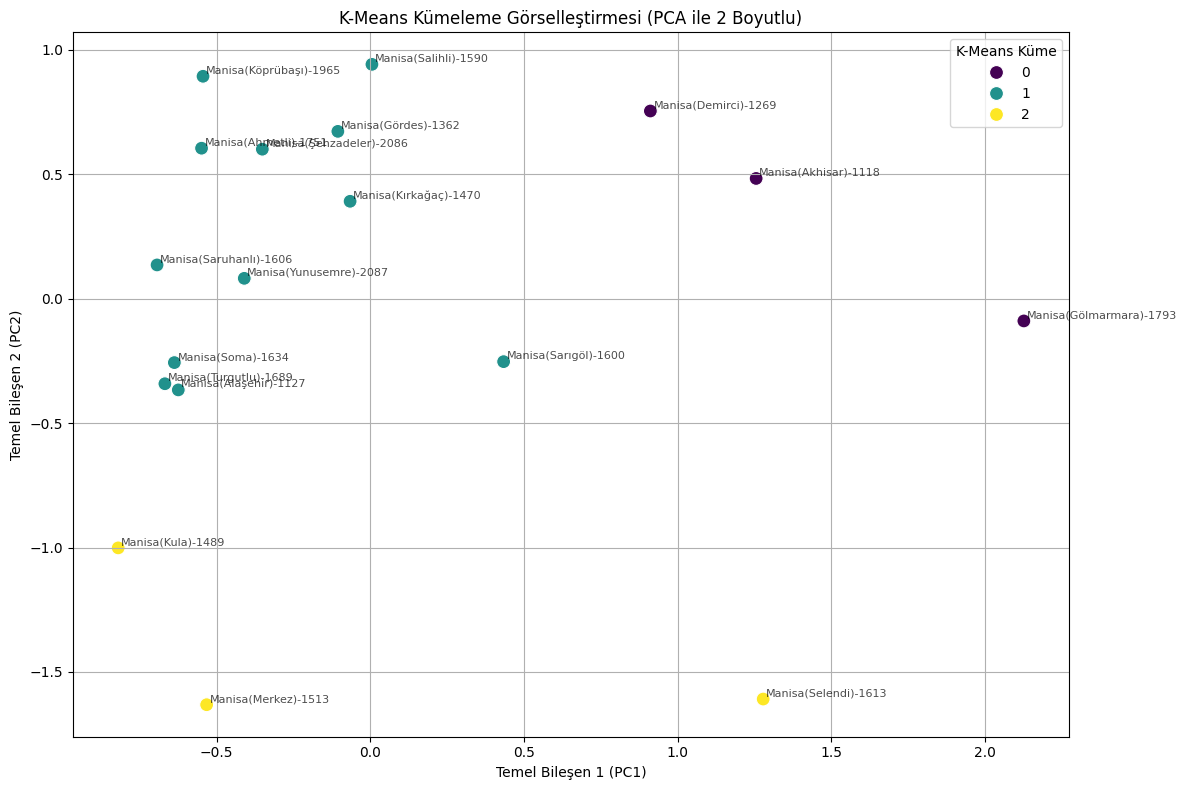

In [ ]:
from sklearn.decomposition import PCA

# Veriyi 2 ana bileşene indirgeme
pca = PCA(n_components=2)
principal_components = pca.fit_transform(kmeans_icin_veri)

# PCA sonuçlarını ve küme etiketlerini bir DataFrame'e ekleme
pca_df = pd.DataFrame(data = principal_components, columns = ['PC1', 'PC2'])
pca_df['District'] = kmeans_icin_veri.index
pca_df['KMeans_Cluster'] = kmeans_kume_numaralari
pca_df['Hierarchical_Cluster'] = hiyerarsik_kume_numaralari

# K-Means Kümeleme Görselleştirmesi
plt.figure(figsize=(12, 8))
sns.scatterplot(x='PC1', y='PC2', hue='KMeans_Cluster', data=pca_df, palette='viridis', s=100, legend='full')
for i, row in pca_df.iterrows():
    plt.text(row['PC1'] + 0.01, row['PC2'] + 0.01, row['District'], fontsize=8, alpha=0.7)
plt.title('K-Means Kümeleme Görselleştirmesi (PCA ile 2 Boyutlu)')
plt.xlabel('Temel Bileşen 1 (PC1)')
plt.ylabel('Temel Bileşen 2 (PC2)')
plt.grid(True)
plt.legend(title='K-Means Küme')
plt.tight_layout()
plt.show()

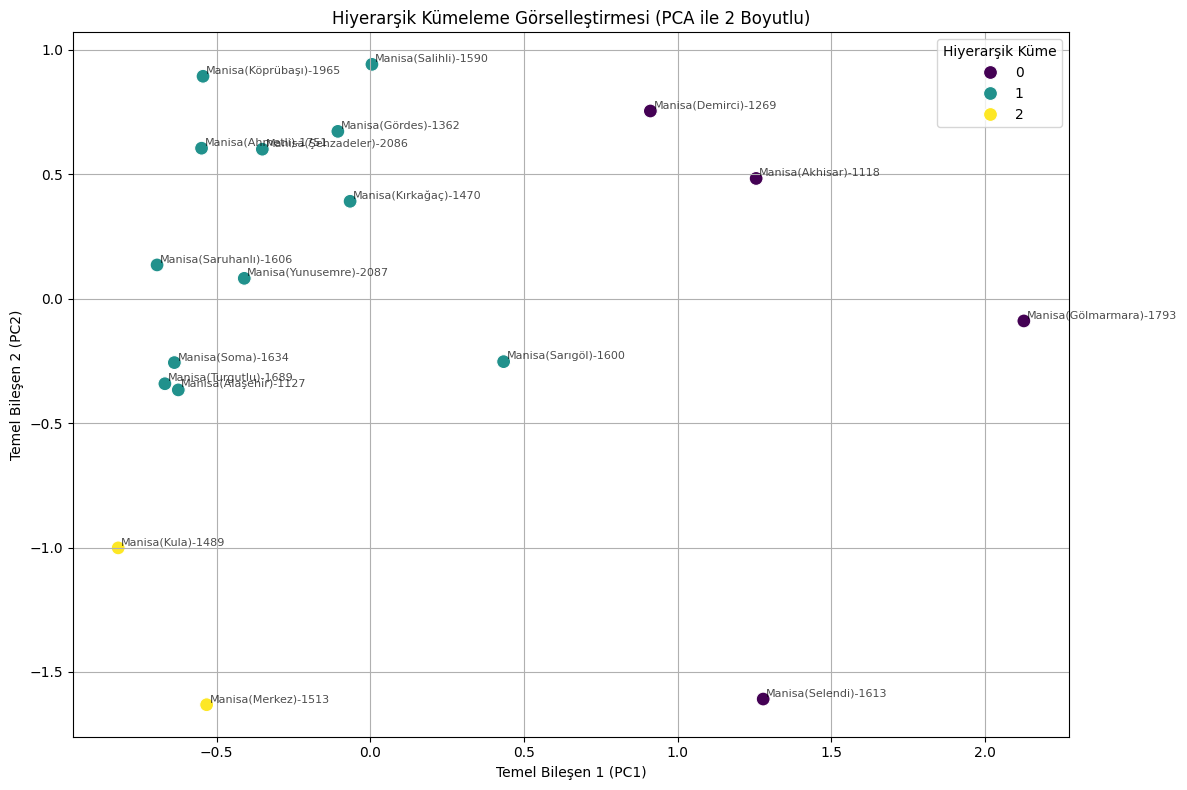

In [ ]:
# Hiyerarşik Kümeleme Görselleştirmesi
plt.figure(figsize=(12, 8))
sns.scatterplot(x='PC1', y='PC2', hue='Hierarchical_Cluster', data=pca_df, palette='viridis', s=100, legend='full')
for i, row in pca_df.iterrows():
    plt.text(row['PC1'] + 0.01, row['PC2'] + 0.01, row['District'], fontsize=8, alpha=0.7)
plt.title('Hiyerarşik Kümeleme Görselleştirmesi (PCA ile 2 Boyutlu)')
plt.xlabel('Temel Bileşen 1 (PC1)')
plt.ylabel('Temel Bileşen 2 (PC2)')
plt.grid(True)
plt.legend(title='Hiyerarşik Küme')
plt.tight_layout()
plt.show()

In [ ]:
# Küme üyelerini gösterme
print("\nK-Means Küme Üyeleri:")
for cluster_id in sorted(pca_df['KMeans_Cluster'].unique()):
    print(f"Küme {cluster_id}:")
    print(pca_df[pca_df['KMeans_Cluster'] == cluster_id]['District'].tolist())

print("\nHiyerarşik Küme Üyeleri:")
for cluster_id in sorted(pca_df['Hierarchical_Cluster'].unique()):
    print(f"Küme {cluster_id}:")
    print(pca_df[pca_df['Hierarchical_Cluster'] == cluster_id]['District'].tolist())


K-Means Küme Üyeleri:
Küme 0:
['Manisa(Akhisar)-1118', 'Manisa(Demirci)-1269', 'Manisa(Gölmarmara)-1793']
Küme 1:
['Manisa(Ahmetli)-1751', 'Manisa(Alaşehir)-1127', 'Manisa(Gördes)-1362', 'Manisa(Köprübaşı)-1965', 'Manisa(Kırkağaç)-1470', 'Manisa(Salihli)-1590', 'Manisa(Saruhanlı)-1606', 'Manisa(Sarıgöl)-1600', 'Manisa(Soma)-1634', 'Manisa(Turgutlu)-1689', 'Manisa(Yunusemre)-2087', 'Manisa(Şehzadeler)-2086']
Küme 2:
['Manisa(Kula)-1489', 'Manisa(Merkez)-1513', 'Manisa(Selendi)-1613']

Hiyerarşik Küme Üyeleri:
Küme 0:
['Manisa(Akhisar)-1118', 'Manisa(Demirci)-1269', 'Manisa(Gölmarmara)-1793', 'Manisa(Selendi)-1613']
Küme 1:
['Manisa(Ahmetli)-1751', 'Manisa(Alaşehir)-1127', 'Manisa(Gördes)-1362', 'Manisa(Köprübaşı)-1965', 'Manisa(Kırkağaç)-1470', 'Manisa(Salihli)-1590', 'Manisa(Saruhanlı)-1606', 'Manisa(Sarıgöl)-1600', 'Manisa(Soma)-1634', 'Manisa(Turgutlu)-1689', 'Manisa(Yunusemre)-2087', 'Manisa(Şehzadeler)-2086']
Küme 2:
['Manisa(Kula)-1489', 'Manisa(Merkez)-1513']


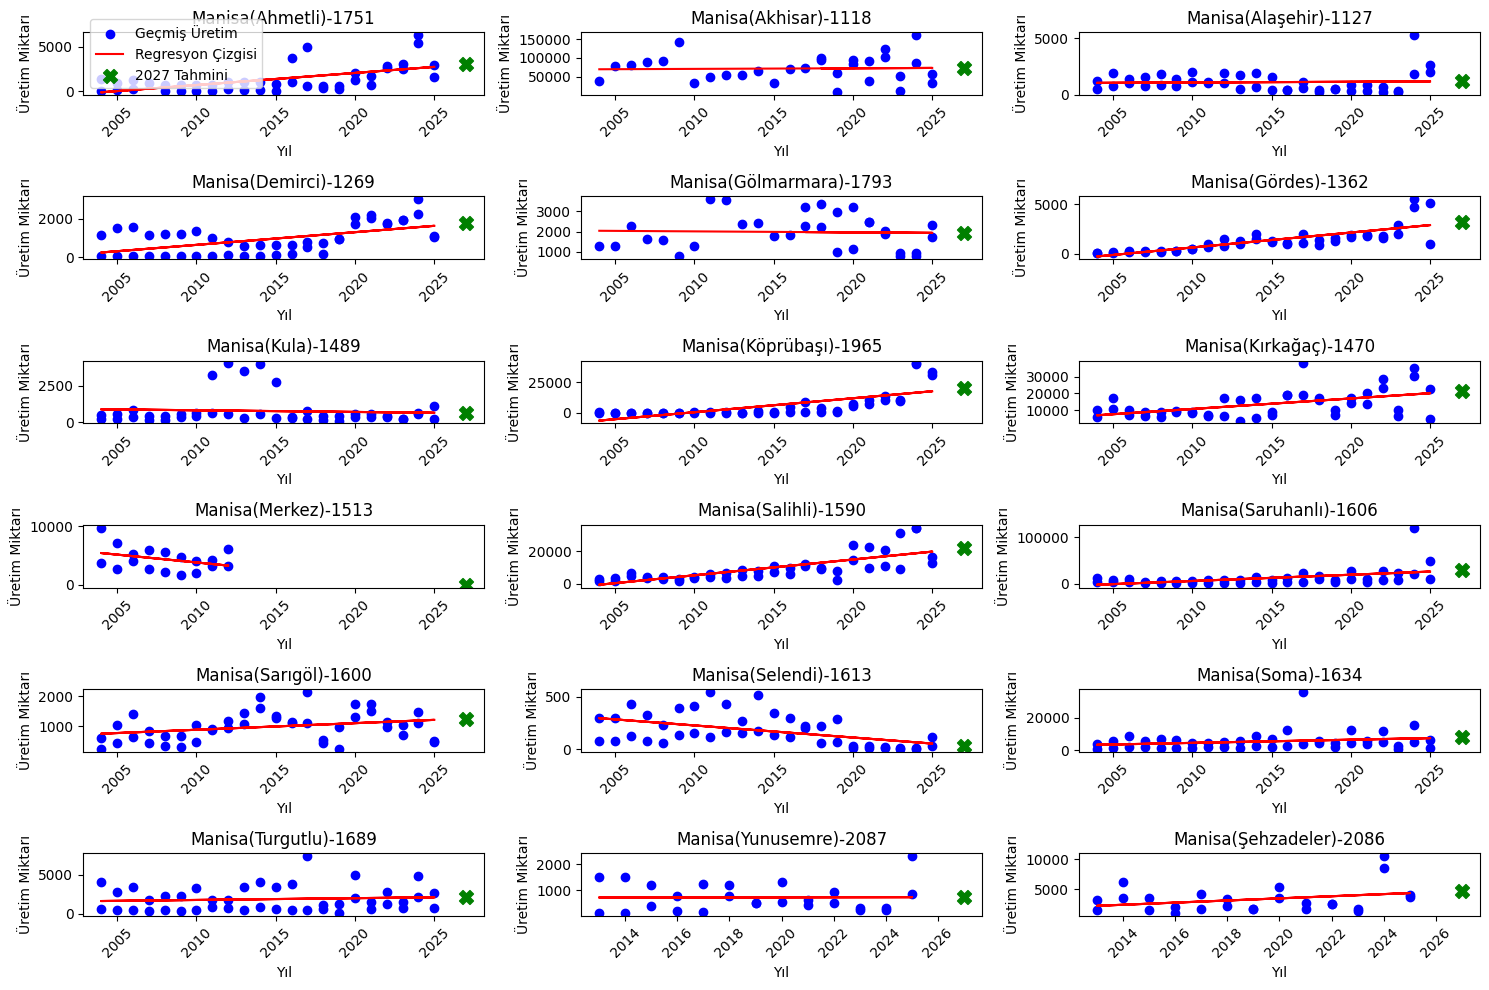


2027 Yılı İlçe Bazında Tahmini Üretim Miktarları (Ton):
Manisa(Ahmetli)-1751: 3013.07 Ton
Manisa(Akhisar)-1118: 73514.01 Ton
Manisa(Alaşehir)-1127: 1201.57 Ton
Manisa(Demirci)-1269: 1760.40 Ton
Manisa(Gölmarmara)-1793: 1923.40 Ton
Manisa(Gördes)-1362: 3191.23 Ton
Manisa(Kula)-1489: 632.86 Ton
Manisa(Köprübaşı)-1965: 19906.87 Ton
Manisa(Kırkağaç)-1470: 21401.85 Ton
Manisa(Merkez)-1513: 0.00 Ton
Manisa(Salihli)-1590: 21632.15 Ton
Manisa(Saruhanlı)-1606: 28810.81 Ton
Manisa(Sarıgöl)-1600: 1252.52 Ton
Manisa(Selendi)-1613: 29.86 Ton
Manisa(Soma)-1634: 7894.51 Ton
Manisa(Turgutlu)-1689: 2142.04 Ton
Manisa(Yunusemre)-2087: 739.64 Ton
Manisa(Şehzadeler)-2086: 4744.32 Ton


In [ ]:
from sklearn.linear_model import LinearRegression

# Veriyi regresyon için hazırlama
# Her ilçe sütunu için ayrı bir model eğiteceğiz.

years = temiz_veri['Yil'].unique()
if len(years) < 2:
    print("Uyarı: Doğrusal regresyon için yeterli yıl verisi bulunmuyor. En az iki farklı yıl olmalıdır.")
    # Hata durumunda boş DataFrame döndür veya uygun bir işlem yap

prediction_year = 2027
predicted_production = {}

plt.figure(figsize=(15, 10))

for i, ilce in enumerate(ilce_isimleri):
    # Her ilçe için 'Yil' ve ilgili ilçe sütununu seç
    df_ilce = temiz_veri[['Yil', ilce]].copy()
    df_ilce = df_ilce[df_ilce[ilce] > 0] # Sadece üretimi olan yılları dikkate al

    if df_ilce.empty or len(df_ilce['Yil'].unique()) < 2: # Regresyon için en az 2 nokta gerekli
        print(f"Uyarı: {ilce} için yeterli veri bulunamadığından tahmin yapılmayacaktır.")
        predicted_production[ilce] = None
        continue

    X = df_ilce['Yil'].values.reshape(-1, 1)
    y = df_ilce[ilce].values

    # Doğrusal regresyon modeli oluşturma ve eğitme
    model = LinearRegression()
    model.fit(X, y)

    # 2027 yılı için tahmin yapma
    prediction = model.predict(np.array([[prediction_year]]))[0]
    predicted_production[ilce] = max(0, prediction) # Negatif tahmini 0 yap

    # Grafiği çizdirme (her ilçe için ayrı bir subplot)
    plt.subplot(6, 3, i + 1) # Örnek: 6 satır, 3 sütun. Toplam 18 ilçe için uygun
    plt.scatter(X, y, color='blue', label='Geçmiş Üretim')
    plt.plot(X, model.predict(X), color='red', label='Regresyon Çizgisi')
    plt.scatter(prediction_year, predicted_production[ilce], color='green', marker='X', s=100, label='2027 Tahmini')

    plt.title(f'{ilce}')
    plt.xlabel('Yıl')
    plt.ylabel('Üretim Miktarı')
    plt.xticks(rotation=45)
    # Sadece ilk grafiğe legend ekle
    if i == 0:
        plt.legend()

plt.tight_layout()
plt.show()

# Tahmin sonuçlarını gösterme
print("\n2027 Yılı İlçe Bazında Tahmini Üretim Miktarları (Ton):")
for ilce, production in predicted_production.items():
    if production is not None:
        print(f"{ilce}: {production:.2f} Ton")
    else:
        print(f"{ilce}: Yetersiz veri nedeniyle tahmin yapılamadı.")

### 2027 Yılı Üretim Tahmini (Daha Basit Anlatım)

Şimdi, 2027 yılı için her bir ilçenin ne kadar ürün üreteceğini tahmin edelim. Bunu yapmak için, her ilçenin geçmiş yıllardaki üretim verilerini kullanıp, bu verilere uyan düz bir çizgi çizmeye çalışacağız (buna 'doğrusal regresyon' diyoruz). Bu çizgi sayesinde, 2027 yılının neresine denk geldiğini bulup, o noktadaki tahmini üretim miktarını belirleyeceğiz.

**"Formül" dediğimiz şey ne?**
Aslında her ilçenin kendi "formülü" olacak. Bu formül, 'yıl' ile 'üretim' arasındaki ilişkiyi gösteren bir denkleme benziyor: `Üretim = A * Yıl + B`. Burada 'A' üretimdeki yıllık değişimi (eğim), 'B' ise başlangıç noktasını (kesişim) temsil ediyor. Bu A ve B sayıları her ilçe için geçmiş verilere göre bilgisayar tarafından hesaplanıyor.


Örnek 'Formül' (Manisa(Ahmetli)-1751 için):
Üretim = 136.05 * Yıl + -272758.90
Bu, her yıl ortalama 136.05 birim üretim değişimi olduğunu gösterir.

--- Tahminler Tamamlandı ---


/tmp/ipykernel_8187/2250540835.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Tahmini Üretim (Ton)', y='İlçe', data=tahmin_df, palette='viridis')


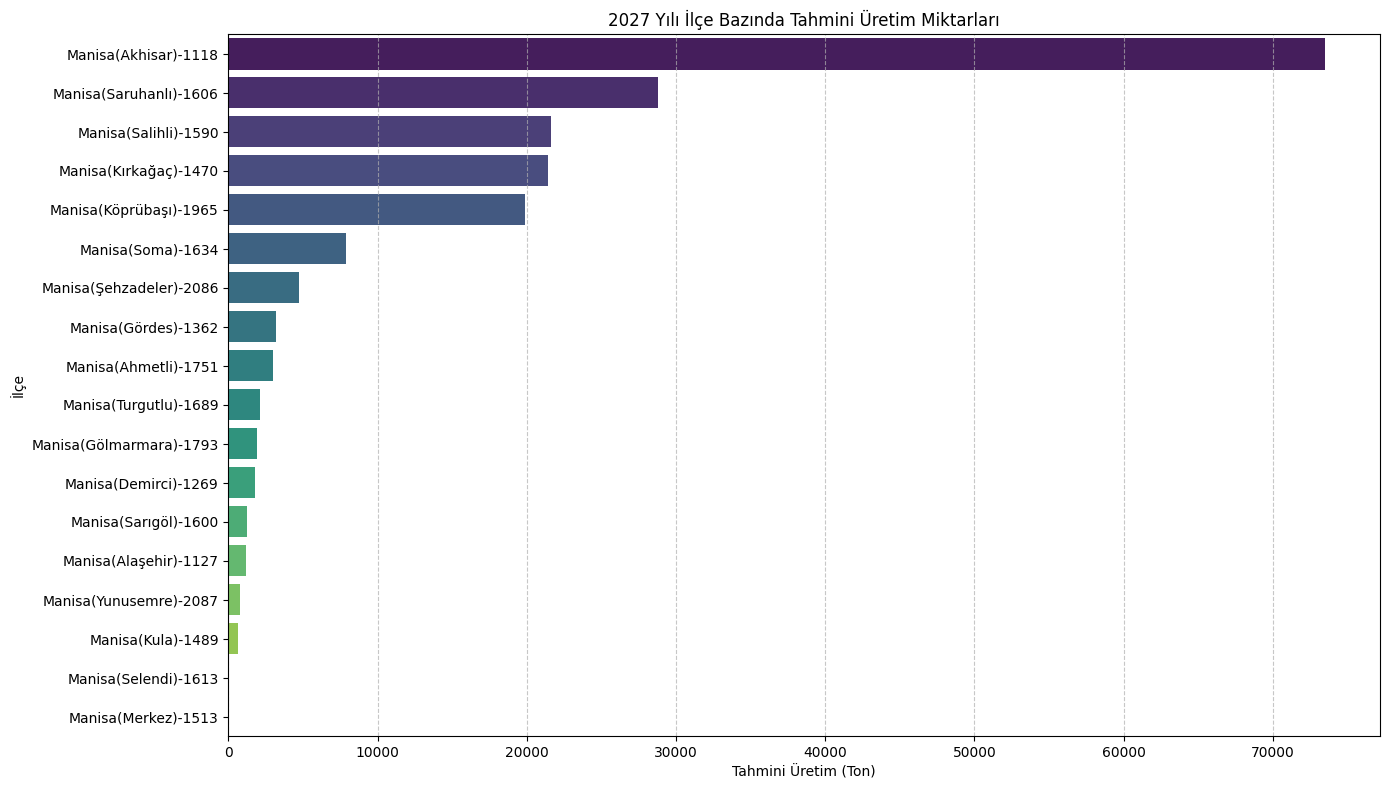


2027 Yılı İlçe Bazında Tahmini Üretim Miktarları (Ton):
Manisa(Ahmetli)-1751: 3013.07 Ton
Manisa(Akhisar)-1118: 73514.01 Ton
Manisa(Alaşehir)-1127: 1201.57 Ton
Manisa(Demirci)-1269: 1760.40 Ton
Manisa(Gölmarmara)-1793: 1923.40 Ton
Manisa(Gördes)-1362: 3191.23 Ton
Manisa(Kula)-1489: 632.86 Ton
Manisa(Köprübaşı)-1965: 19906.87 Ton
Manisa(Kırkağaç)-1470: 21401.85 Ton
Manisa(Merkez)-1513: 0.00 Ton
Manisa(Salihli)-1590: 21632.15 Ton
Manisa(Saruhanlı)-1606: 28810.81 Ton
Manisa(Sarıgöl)-1600: 1252.52 Ton
Manisa(Selendi)-1613: 29.86 Ton
Manisa(Soma)-1634: 7894.51 Ton
Manisa(Turgutlu)-1689: 2142.04 Ton
Manisa(Yunusemre)-2087: 739.64 Ton
Manisa(Şehzadeler)-2086: 4744.32 Ton


In [ ]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

prediction_year = 2027
predicted_production = {}

# Her ilçe için ayrı ayrı hesaplama yapıyoruz
for ilce in ilce_isimleri:
    # Bu ilçenin sadece 'Yil' ve kendi üretim verilerini alıyoruz
    df_ilce = temiz_veri[['Yil', ilce]].copy()
    # Sadece üretimin olduğu yılları dikkate alalım
    df_ilce = df_ilce[df_ilce[ilce] > 0]

    # Tahmin yapabilmek için en az 2 yıllık veri olmalı
    if df_ilce.empty or len(df_ilce['Yil'].unique()) < 2:
        print(f"Uyarı: {ilce} için yeterli veri yok, tahmin yapılamadı.")
        predicted_production[ilce] = None
        continue

    # Verileri modelin anlayacağı hale getiriyoruz
    X = df_ilce['Yil'].values.reshape(-1, 1) # Yıl verisi
    y = df_ilce[ilce].values # Üretim verisi

    # Doğrusal regresyon modelimizi oluşturup eğitiyoruz (çizgiyi buluyoruz)
    model = LinearRegression()
    model.fit(X, y)

    # 2027 yılı için tahmin yapıyoruz
    tahmin = model.predict(np.array([[prediction_year]]))[0]
    # Negatif çıkarsa 0 yapıyoruz, çünkü üretim negatif olamaz
    predicted_production[ilce] = max(0, tahmin)

    # İlk ilçe için 'formül' örneklerini gösterelim
    if ilce == ilce_isimleri[0]:
        print(f"\nÖrnek 'Formül' ({ilce} için):\nÜretim = {model.coef_[0]:.2f} * Yıl + {model.intercept_:.2f}")
        print(f"Bu, her yıl ortalama {model.coef_[0]:.2f} birim üretim değişimi olduğunu gösterir.")

print("\n--- Tahminler Tamamlandı ---")

# Tahmin sonuçlarını bir DataFrame'e çevirip daha kolay görselleştirelim
tahmin_df = pd.DataFrame(list(predicted_production.items()), columns=['İlçe', 'Tahmini Üretim (Ton)'])
tahmin_df = tahmin_df.dropna() # Tahmin yapılamayan ilçeleri çıkar
tahmin_df = tahmin_df.sort_values(by='Tahmini Üretim (Ton)', ascending=False)

# Tüm ilçelerin 2027 tahmini üretimini tek bir çubuk grafikte gösterelim
plt.figure(figsize=(14, 8))
sns.barplot(x='Tahmini Üretim (Ton)', y='İlçe', data=tahmin_df, palette='viridis')
plt.title(f'2027 Yılı İlçe Bazında Tahmini Üretim Miktarları')
plt.xlabel('Tahmini Üretim (Ton)')
plt.ylabel('İlçe')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("\n2027 Yılı İlçe Bazında Tahmini Üretim Miktarları (Ton):")
for ilce, production in predicted_production.items():
    if production is not None:
        print(f"{ilce}: {production:.2f} Ton")
    else:
        print(f"{ilce}: Yetersiz veri nedeniyle tahmin yapılamadı.")